## Import Semua Packages/Library yang Digunakan

In [ ]:
!pip install split-folders

In [ ]:
import os
import shutil
import random
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import tensorflow as tf
from PIL import Image
from pathlib import Path
from tensorflow.keras.preprocessing import image
from tensorflow.keras.optimizers import Adam
from tensorflow.keras import layers
from tensorflow.keras.models import Sequential, Model
from tensorflow.keras.callbacks import Callback, EarlyStopping, ModelCheckpoint, ReduceLROnPlateau

import splitfolders
import warnings
warnings.simplefilter(action='ignore', category=FutureWarning)

from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


## Data Preparation

#### Split & Load Dataset

In [ ]:
input_path = '/content/drive/MyDrive/dataset'
output_path = '/content/drive/MyDrive/dataset_split'
train_path = '/content/drive/MyDrive/dataset_split/train'
val_path = '/content/drive/MyDrive/dataset_split/val'
test_path = '/content/drive/MyDrive/dataset_split/test'
items = os.listdir(input_path)
print(items)

splitfolders.ratio(input_path, output=output_path, seed=42, ratio=(.8,.1,.1), group_prefix=None)
items_splitting = os.listdir(output_path)
items_splitting
itemst = os.listdir(train_path)
itemst

train_dir = []
test_dir = []
validation_dir = []
for item in items :
  train_dir.append(train_path + '/' + item + '/')
  validation_dir.append(val_path + '/' + item + '/')
  test_dir.append(test_path + '/' + item + '/')

['forest', 'buildings', 'glacier', 'mountain', 'street', 'sea']


Copying files: 16901 files [08:17, 33.96 files/s]


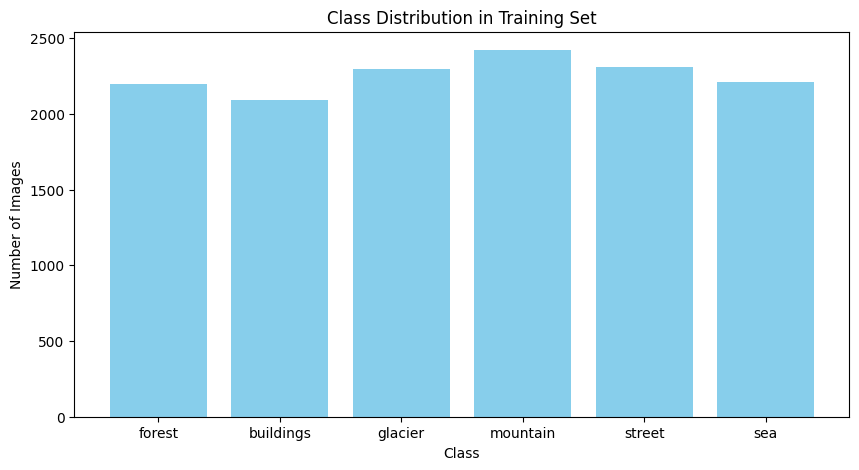

In [ ]:
class_names = [
    folder for folder in os.listdir(input_path)
    if os.path.isdir(os.path.join(input_path, folder))
    and folder not in ['train', 'val', 'test']
]

img_format = ('jpg', 'jpeg', 'png', 'bmp', 'webp')
class_counts = []
for class_name in class_names:
  class_dir = os.path.join(train_path, class_name)
  if os.path.exists(class_dir):
    files = [f for f in os.listdir(class_dir) if f.lower().endswith(img_format)]
    class_counts.append(len(files))
  else:
    class_counts.append(0)

plt.figure(figsize=(10, 5))
plt.bar(class_names, class_counts, color='skyblue')
plt.title("Class Distribution in Training Set")
plt.xlabel("Class")
plt.ylabel("Number of Images")
plt.show()

In [ ]:
def print_images_resolution(directory):
    unique_sizes = set()
    total_images = 0

    for subdir in os.listdir(directory):
        subdir_path = os.path.join(directory, subdir)
        image_files = os.listdir(subdir_path)
        num_images = len(image_files)
        print(f"{subdir}: {num_images}")
        total_images += num_images

        for img_file in image_files:
            img_path = os.path.join(subdir_path, img_file)
            with Image.open(img_path) as img:
                unique_sizes.add(img.size)

        for size in unique_sizes:
            print(f"- {size}")
        print("---------------")

    print(f"\nTotal: {total_images}")

print_images_resolution(train_path)
print_images_resolution(val_path)
print_images_resolution(test_path)

forest: 2196
- (150, 136)
- (150, 113)
- (150, 135)
- (150, 115)
- (150, 150)
- (150, 108)
- (150, 133)
---------------
buildings: 2088
- (150, 136)
- (150, 113)
- (150, 135)
- (150, 115)
- (150, 150)
- (150, 124)
- (150, 108)
- (150, 133)
---------------
glacier: 2299
- (150, 136)
- (150, 142)
- (150, 102)
- (150, 108)
- (150, 111)
- (150, 120)
- (150, 123)
- (150, 135)
- (150, 150)
- (150, 110)
- (150, 113)
- (150, 76)
- (150, 134)
- (150, 143)
- (150, 146)
- (150, 97)
- (150, 115)
- (150, 124)
- (150, 133)
- (150, 72)
---------------
mountain: 2421
- (150, 136)
- (150, 81)
- (150, 145)
- (150, 142)
- (150, 102)
- (150, 108)
- (150, 111)
- (150, 120)
- (150, 123)
- (150, 135)
- (150, 141)
- (150, 144)
- (150, 150)
- (150, 147)
- (150, 110)
- (150, 113)
- (150, 131)
- (150, 76)
- (150, 134)
- (150, 143)
- (150, 146)
- (150, 100)
- (150, 97)
- (150, 103)
- (150, 115)
- (150, 124)
- (150, 133)
- (150, 72)
---------------
street: 2306
- (150, 136)
- (150, 81)
- (150, 145)
- (150, 142)
- 

In [ ]:
img_size = (224, 224)
batch_size = 32

train = tf.keras.utils.image_dataset_from_directory(
  train_path,
  image_size=img_size,
  batch_size=batch_size,
  shuffle=True,
)

val = tf.keras.utils.image_dataset_from_directory(
  val_path,
  image_size=img_size,
  batch_size=batch_size,
  shuffle=False,
)

test = tf.keras.utils.image_dataset_from_directory(
  test_path,
  image_size=img_size,
  batch_size=batch_size,
  shuffle=False,
)

Found 13519 files belonging to 6 classes.
Found 1688 files belonging to 6 classes.
Found 1694 files belonging to 6 classes.


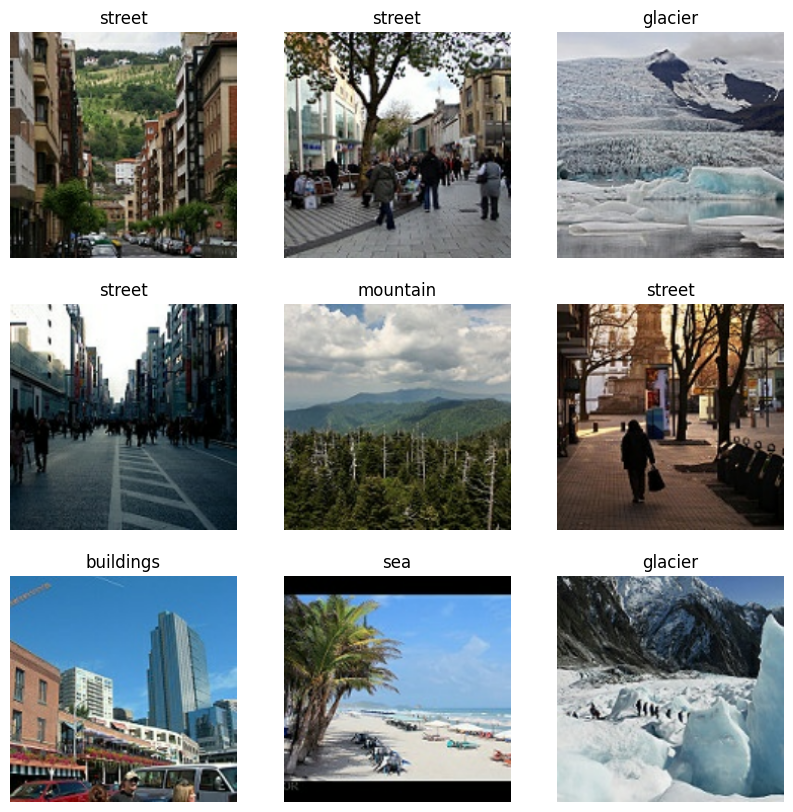

In [ ]:
plt.figure(figsize=(10, 10))
for images, labels in train.take(1):
    for i in range(9):
        plt.subplot(3, 3, i + 1)
        plt.imshow(images[i].numpy().astype('uint8'))
        plt.title(train.class_names[labels[i]])
        plt.axis('off')
plt.show()

### Data Preprocessing

In [ ]:
train_norm = train.map(lambda x, y: (x / 255.0, y))
val_norm = val.map(lambda x, y: (x / 255.0, y))
test_norm = test.map(lambda x, y: (x / 255.0, y))
class_names = [
    folder for folder in os.listdir(input_path)
    if os.path.isdir(os.path.join(input_path, folder))
    and folder not in ['train', 'val', 'test']
]
num_classes = len(class_names)

for gambar, label in train_norm.take(1):
  print("Shape gambar:", gambar.shape)
  print("Shape label:", label.shape)
  print("Nilai piksel minimum:", tf.reduce_min(gambar).numpy())
  print("Nilai piksel maksimum:", tf.reduce_max(gambar).numpy())

Shape gambar: (32, 224, 224, 3)
Shape label: (32,)
Nilai piksel minimum: 0.0
Nilai piksel maksimum: 1.0


## Modelling

In [ ]:
data_aug = Sequential([
    layers.RandomFlip("horizontal"),
    layers.RandomZoom(0.1),
    layers.RandomContrast(0.1),
])

model = Sequential([
    layers.Input(img_size + (3,)),
    data_aug,

    layers.Conv2D(32, 3),
    layers.LeakyReLU(negative_slope=0.01),
    layers.BatchNormalization(),
    layers.MaxPooling2D(),

    layers.Conv2D(64, 3),
    layers.LeakyReLU(negative_slope=0.01),
    layers.BatchNormalization(),
    layers.MaxPooling2D(),

    layers.Conv2D(128, 3),
    layers.LeakyReLU(negative_slope=0.01),
    layers.BatchNormalization(),
    layers.MaxPooling2D(),

    layers.Conv2D(128, 3),
    layers.LeakyReLU(negative_slope=0.01),
    layers.BatchNormalization(),
    layers.MaxPooling2D(),

    layers.GlobalAveragePooling2D(),
    layers.Dropout(0.3),
    layers.Dense(num_classes, activation='softmax')
])

model.summary()

Model: "sequential_5"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ sequential_4 (Sequential)       │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_8 (Conv2D)               │ (None, 222, 222, 32)   │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ leaky_re_lu_8 (LeakyReLU)       │ (None, 222, 222, 32)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_8           │ (None, 222, 222, 32)   │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_8 (MaxPooling2D)  │ (None, 111, 111, 32)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_9 (Conv2D)               │ (None, 109, 109, 64)   │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ leaky_re_lu_9 (LeakyReLU)       │ (None, 109, 109, 64)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_9           │ (None, 109, 109, 64)   │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_9 (MaxPooling2D)  │ (None, 54, 54, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_10 (Conv2D)              │ (None, 52, 52, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ leaky_re_lu_10 (LeakyReLU)      │ (None, 52, 52, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_10          │ (None, 52, 52, 128)    │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_10 (MaxPooling2D) │ (None, 26, 26, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_11 (Conv2D)              │ (None, 24, 24, 128)    │       147,584 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ leaky_re_lu_11 (LeakyReLU)      │ (None, 24, 24, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_11          │ (None, 24, 24, 128)    │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_11 (MaxPooling2D) │ (None, 12, 12, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d_2      │ (None, 128)            │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_2 (Dropout)             │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 6)              │           774 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 243,014 (949.27 KB)

 Trainable params: 242,310 (946.52 KB)

 Non-trainable params: 704 (2.75 KB)

In [ ]:
model.compile(
  optimizer=Adam(),
  loss='sparse_categorical_crossentropy',
  metrics=['accuracy']
)

stop = [
    EarlyStopping(monitor='val_loss', patience=10, restore_best_weights=True, verbose=1),
    ModelCheckpoint('best_model.keras', monitor='val_accuracy', save_best_only=True),
    ReduceLROnPlateau(monitor='val_loss', factor=0.5, patience=5, min_lr=1e-6)
    ]

history = model.fit(
  train_norm,
  validation_data=val_norm,
  epochs=50,
  batch_size=batch_size,
  callbacks=stop,
  verbose=1
)

loss, accuracy = model.evaluate(test_norm)

Epoch 1/50
423/423 ━━━━━━━━━━━━━━━━━━━━ 61s 139ms/step - accuracy: 0.6609 - loss: 0.8680 - val_accuracy: 0.3768 - val_loss: 1.6723 - learning_rate: 0.0010
Epoch 2/50
423/423 ━━━━━━━━━━━━━━━━━━━━ 81s 137ms/step - accuracy: 0.7765 - loss: 0.6063 - val_accuracy: 0.7838 - val_loss: 0.6140 - learning_rate: 0.0010
Epoch 3/50
423/423 ━━━━━━━━━━━━━━━━━━━━ 57s 135ms/step - accuracy: 0.8155 - loss: 0.5052 - val_accuracy: 0.8241 - val_loss: 0.5326 - learning_rate: 0.0010
Epoch 4/50
423/423 ━━━━━━━━━━━━━━━━━━━━ 56s 133ms/step - accuracy: 0.8294 - loss: 0.4778 - val_accuracy: 0.8430 - val_loss: 0.4555 - learning_rate: 0.0010
Epoch 5/50
423/423 ━━━━━━━━━━━━━━━━━━━━ 58s 138ms/step - accuracy: 0.8410 - loss: 0.4332 - val_accuracy: 0.8063 - val_loss: 0.5139 - learning_rate: 0.0010
Epoch 6/50
423/423 ━━━━━━━━━━━━━━━━━━━━ 61s 144ms/step - accuracy: 0.8548 - loss: 0.4099 - val_accuracy: 0.7695 - val_loss: 0.6134 - learning_rate: 0.0010
Epoch 7/50
423/423 ━━━━━━━━━━━━━━━━━━━━ 59s 138ms/step - accuracy: 0.8

## Evaluasi dan Visualisasi

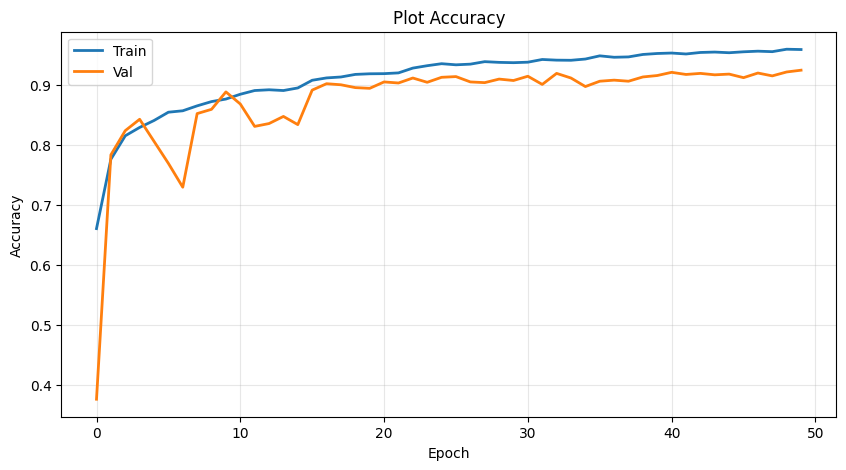

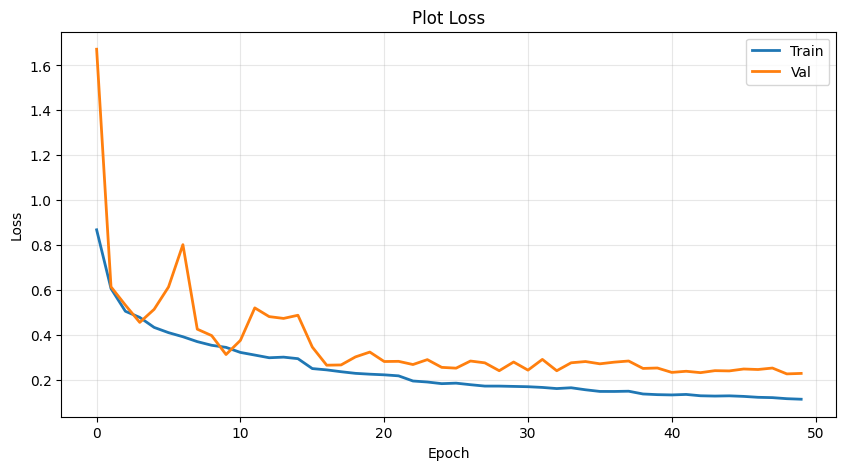


Accuracy: 91.62%


In [ ]:
# Plot Akurasi
plt.figure(figsize=(10, 5))
plt.plot(history.history['accuracy'], label='Train', linewidth=2)
plt.plot(history.history['val_accuracy'], label='Val', linewidth=2)
plt.title('Plot Accuracy')
plt.xlabel('Epoch')
plt.ylabel('Accuracy')
plt.legend()
plt.grid(True, alpha=0.3)
plt.show()

# Plot Loss
plt.figure(figsize=(10, 5))
plt.plot(history.history['loss'], label='Train', linewidth=2)
plt.plot(history.history['val_loss'], label='Val', linewidth=2)
plt.title('Plot Loss')
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.legend()
plt.grid(True, alpha=0.3)
plt.show()

print(f'\nAccuracy: {accuracy * 100:.2f}%')

53/53 ━━━━━━━━━━━━━━━━━━━━ 3s 58ms/step


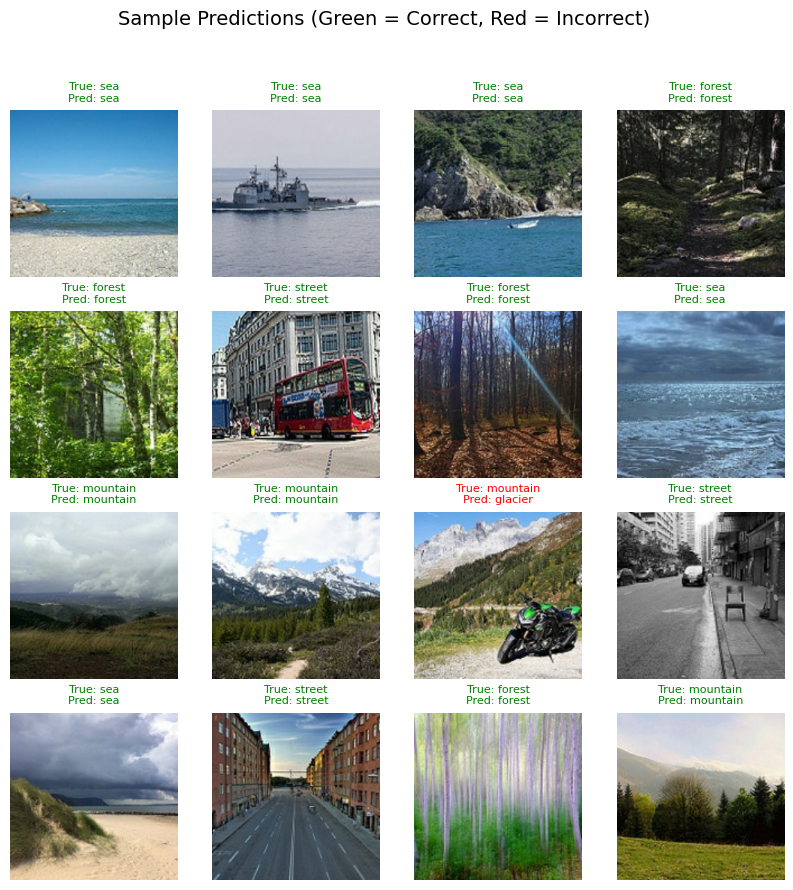

In [ ]:
x_test_list = []
y_test_list = []

for images, labels in test_norm:
    x_test_list.append(images.numpy())
    y_test_list.append(labels.numpy())

x_test = np.concatenate(x_test_list, axis=0)
y_true_classes = np.concatenate(y_test_list, axis=0)

y_pred_probs = model.predict(test_norm)
y_pred_classes = np.argmax(y_pred_probs, axis=1)

plt.figure(figsize=(10, 10))
for i in range(16):
    index = np.random.randint(0, len(x_test))
    plt.subplot(4, 4, i + 1)

    plt.imshow(x_test[index])

    true_label = train.class_names[y_true_classes[index]]
    pred_label = train.class_names[y_pred_classes[index]]
    color = 'green' if true_label == pred_label else 'red'

    plt.title(f"True: {true_label}\nPred: {pred_label}", color=color, fontsize=8)
    plt.axis("off")

plt.suptitle("Sample Predictions (Green = Correct, Red = Incorrect)", fontsize=14)
plt.show()

In [ ]:
base_model = tf.keras.applications.MobileNetV2(
    input_shape=(IMG_SIZE, IMG_SIZE, 3),
    include_top=False,  # buang layer klasifikasi bawaan ImageNet (1000 kelas), kita ganti head sendiri
    weights='imagenet'  # bobot hasil pretrain di jutaan gambar ImageNet
)
base_model.trainable = False  # fase 1: bekukan semua bobot base model, cuma head di bawah yang dilatih

model_tl = tf.keras.Sequential([
    layers.Input(shape=(IMG_SIZE, IMG_SIZE, 3)),
    data_aug,  # augmentasi yang sama kayak model CNN, cuma aktif pas training
    layers.Rescaling(1./127.5, offset=-1),  # skala pixel ke -1..1, sesuai preprocessing standar MobileNetV2 (beda sama CNN yang pake 0..1)
    base_model,  # ekstraksi fitur pakai bobot pretrained
    layers.GlobalAveragePooling2D(),  # ratakan feature map jadi 1 vektor per gambar
    layers.Dropout(0.3),  # cegah overfitting di head yang baru
    layers.Dense(num_classes, activation='softmax'),  # output probabilitas per kelas bunga
])

model_tl.summary()

## Konversi Model

In [ ]:
# Model -> Saved_Model
sub_path = '/content/drive/MyDrive/Submission'
sm_path = '/content/drive/MyDrive/Submission/Saved_model'
os.makedirs(sm_path, exist_ok=True)

sm_export = Sequential([
    layers.Input(img_size + (3,)),
    *[l for l in model.layers if l is not data_aug],
])

sm_export.export(sm_path)
print(f'\nModel saved to: {sm_path}')

Saved artifact at '/content/drive/MyDrive/Submission/Saved_model'. The following endpoints are available:

* Endpoint 'serve'
  args_0 (POSITIONAL_ONLY): TensorSpec(shape=(None, 224, 224, 3), dtype=tf.float32, name='keras_tensor_75')
Output Type:
  TensorSpec(shape=(None, 6), dtype=tf.float32, name=None)
Captures:
  136631099528144: TensorSpec(shape=(), dtype=tf.resource, name=None)
  136631099539088: TensorSpec(shape=(), dtype=tf.resource, name=None)
  136631099538320: TensorSpec(shape=(), dtype=tf.resource, name=None)
  136631099538128: TensorSpec(shape=(), dtype=tf.resource, name=None)
  136631099528336: TensorSpec(shape=(), dtype=tf.resource, name=None)
  136631099539280: TensorSpec(shape=(), dtype=tf.resource, name=None)
  136631099538512: TensorSpec(shape=(), dtype=tf.resource, name=None)
  136631099536208: TensorSpec(shape=(), dtype=tf.resource, name=None)
  136631099537936: TensorSpec(shape=(), dtype=tf.resource, name=None)
  136631099537552: TensorSpec(shape=(), dtype=tf.resou

In [ ]:
# Convert Saved Model -> TFLite
tfl_path = '/content/drive/MyDrive/Submission/TFL'
os.makedirs(tfl_path, exist_ok=True)

tfl_converter = tf.lite.TFLiteConverter.from_saved_model(sm_path)
tfl_model = tfl_converter.convert()

tfl_file = os.path.join(tfl_path, 'model.tflite')
with open(tfl_file, 'wb') as f:
  f.write(tfl_model)
print(f'\nModel saved to: {tfl_file}')

label_file = os.path.join(tfl_path, 'label.txt')
with open(label_file, 'w', encoding='utf-8') as f:
  for class_name in class_names:
    f.write(f'{class_name}\n')

print(f'\nLabel saved to: {tfl_path}')


Model saved to: /content/drive/MyDrive/Submission/TFL/model.tflite

Label saved to: /content/drive/MyDrive/Submission/TFL


## Inference (Optional)

In [ ]:
tflite_path = '/content/drive/MyDrive/Submission/TFL/model.tflite'
label_path = '/content/drive/MyDrive/Submission/TFL/label.txt'
pict_path = '/content/drive/MyDrive/test.jpg'
img_size = (224, 224)
with open(label_path, 'r', encoding='utf-8') as f:
  class_names = [line.strip() for line in f if line.strip()]

interpreter = tf.lite.Interpreter(model_path=tflite_path)
interpreter.allocate_tensors()

input_details = interpreter.get_input_details()
output_details = interpreter.get_output_details()

img = tf.keras.utils.load_img(pict_path, target_size=img_size)
img_array = tf.keras.utils.img_to_array(img).astype(np.float32)

img_array = np.expand_dims(img_array, axis=0)

input_dtype = input_details[0]['dtype']

if np.issubdtype(input_dtype, np.floating):
  img_array = img_array.astype(input_dtype) / 255.0
else:
  scale, zero_point = input_details[0]['quantization']
  if scale > 0:
    img_array = img_array / 255.0
    img_array = np.round(img_array / scale + zero_point)

  img_array = np.clip(
      img_array,
      np.iinfo(input_dtype).min,
      np.iinfo(input_dtype).max
  ).astype(input_dtype)

interpreter.set_tensor(input_details[0]['index'], img_array)

# Inference
interpreter.invoke()
predictions = interpreter.get_tensor(output_details[0]['index'])[0]

#Dequantization
output_dtype = output_details[0]['dtype']
output_scale, output_zero_point = output_details[0]['quantization']

if not np.issubdtype(output_dtype, np.floating) and output_scale > 0:
    predictions = (
        predictions.astype(np.float32) - output_zero_point
    ) * output_scale

# skor
predicted_index = int(np.argmax(predictions))
predicted_label = class_names[predicted_index]
confidence = float(predictions[predicted_index])

print('Predicted class:', predicted_label)
print(f'Confidence: {confidence:.2%}')

Predicted class: mountain
Confidence: 93.96%


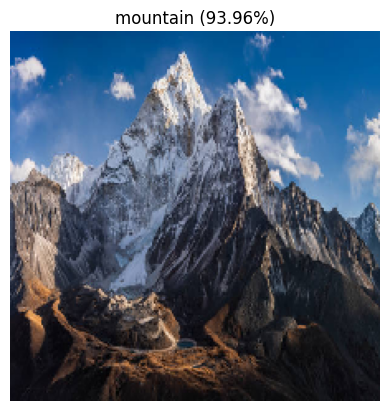

In [ ]:
plt.imshow(img)
plt.title(f'{predicted_label} ({confidence:.2%})')
plt.axis('off')
plt.show()